In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [2]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score
)


In [3]:
df = pd.read_json("input_annotations/ICTY_doccano_import.json")
df.to_csv("input_annotations/ICTY_doccano_import.csv", index=False)

In [4]:
df.head()

,text,label,unique_id,doc_id,sentence_index,meta
0,No.,[none],krajisnik_Public_Transcript_of_Hearing_09_June...,NaN,0,{'previous_utterance': 'And this portion of th...
1,I don't know what this man wrote here but I ca...,[agency],krajisnik_Public_Transcript_of_Hearing_09_June...,NaN,1,{'previous_utterance': 'And this portion of th...
2,And the man here says that the political leade...,[none],krajisnik_Public_Transcript_of_Hearing_09_June...,NaN,2,{'previous_utterance': 'And this portion of th...
3,It was just divided into two halves.,[none],krajisnik_Public_Transcript_of_Hearing_09_June...,NaN,3,{'previous_utterance': 'And this portion of th...
4,I remember there was a quarrel and I said to t...,[agency],krajisnik_Public_Transcript_of_Hearing_09_June...,NaN,4,{'previous_utterance': 'And this portion of th...


In [5]:
df = df.drop(columns=["meta", "doc_id"])

In [6]:
print(df["label"].head())
print(type(df["label"].iloc[0]))

0      [none]
1    [agency]
2      [none]
3      [none]
4    [agency]
Name: label, dtype: object
<class 'list'>


In [7]:
df["label"] = df["label"].apply(
    lambda x: x[0] if isinstance(x, list) and x else None
)

In [8]:
mapping = {'none': 0, 'agency': 1, 'externalization': 2}


In [9]:
df['label'] = df['label'].map(mapping)


In [10]:
gt = pd.read_csv("ground_truth.csv")

In [11]:
gt.shape

(575, 6)

In [12]:
gt

,Unnamed: 0,text,unique_id,sentence_index,token_count,label
0,0,No.,krajisnik_Public_Transcript_of_Hearing_09_June...,0,1,0
1,1,I don't know what this man wrote here but I ca...,krajisnik_Public_Transcript_of_Hearing_09_June...,1,55,1
2,2,And the man here says that the political leade...,krajisnik_Public_Transcript_of_Hearing_09_June...,2,19,0
3,3,It was just divided into two halves.,krajisnik_Public_Transcript_of_Hearing_09_June...,3,7,0
4,4,I remember there was a quarrel and I said to t...,krajisnik_Public_Transcript_of_Hearing_09_June...,4,38,1
...,...,...,...,...,...,...
570,581,It's the result of a request that I made.,prlic_and_others_Public_Transcript_of_Hearing_...,0,9,1
571,582,"The date we see is the 8th of November, 1993.",prlic_and_others_Public_Transcript_of_Hearing_...,1,10,0
572,583,"Mate Boban, the Commander-in-Chief, relieves m...",prlic_and_others_Public_Transcript_of_Hearing_...,2,9,0
573,584,All the information is there.,prlic_and_others_Public_Transcript_of_Hearing_...,3,5,0


In [13]:
gt = gt.drop(columns=["Unnamed: 0", "token_count"])

In [14]:
print(f'{df.columns}, {gt.columns}')

Index(['text', 'label', 'unique_id', 'sentence_index'], dtype='object'), Index(['text', 'unique_id', 'sentence_index', 'label'], dtype='object')


In [15]:
comparison = df.merge(
    gt,
    on=["unique_id", "sentence_index", "text"],
    suffixes=("_df", "_gt")
)

print(comparison[["label_df", "label_gt"]].head())

   label_df  label_gt
0         0         0
1         1         1
2         0         0
3         0         0
4         1         1


In [16]:
comparison.shape

(575, 5)

In [17]:
comparison

,text,label_df,unique_id,sentence_index,label_gt
0,No.,0,krajisnik_Public_Transcript_of_Hearing_09_June...,0,0
1,I don't know what this man wrote here but I ca...,1,krajisnik_Public_Transcript_of_Hearing_09_June...,1,1
2,And the man here says that the political leade...,0,krajisnik_Public_Transcript_of_Hearing_09_June...,2,0
3,It was just divided into two halves.,0,krajisnik_Public_Transcript_of_Hearing_09_June...,3,0
4,I remember there was a quarrel and I said to t...,1,krajisnik_Public_Transcript_of_Hearing_09_June...,4,1
...,...,...,...,...,...
570,It's the result of a request that I made.,1,prlic_and_others_Public_Transcript_of_Hearing_...,0,1
571,"The date we see is the 8th of November, 1993.",0,prlic_and_others_Public_Transcript_of_Hearing_...,1,0
572,"Mate Boban, the Commander-in-Chief, relieves m...",2,prlic_and_others_Public_Transcript_of_Hearing_...,2,0
573,All the information is there.,0,prlic_and_others_Public_Transcript_of_Hearing_...,3,0


In [18]:
print(comparison[comparison["label_gt"].isna()])

Empty DataFrame
Columns: [text, label_df, unique_id, sentence_index, label_gt]
Index: []


In [19]:
y_true = comparison["label_gt"]
y_pred = comparison["label_df"]


In [20]:
# Overall metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="macro")
recall = recall_score(y_true, y_pred, average="macro")
f1 = f1_score(y_true, y_pred, average="macro")
kappa = cohen_kappa_score(y_true, y_pred)

In [21]:
print(f"Accuracy:        {accuracy:.3f}")
print(f"Macro Precision: {precision:.3f}")
print(f"Macro Recall:    {recall:.3f}")
print(f"Macro F1:        {f1:.3f}")
print(f"Cohen's κ:       {kappa:.3f}")


Accuracy:        0.864
Macro Precision: 0.812
Macro Recall:    0.866
Macro F1:        0.834
Cohen's κ:       0.750


In [22]:
# Detailed per-class results
print("\nClassification report:")
print(classification_report(y_true, y_pred))



Classification report:
              precision    recall  f1-score   support

           0       0.96      0.86      0.90       374
           1       0.75      0.83      0.79        77
           2       0.73      0.91      0.81       124

    accuracy                           0.86       575
   macro avg       0.81      0.87      0.83       575
weighted avg       0.88      0.86      0.87       575



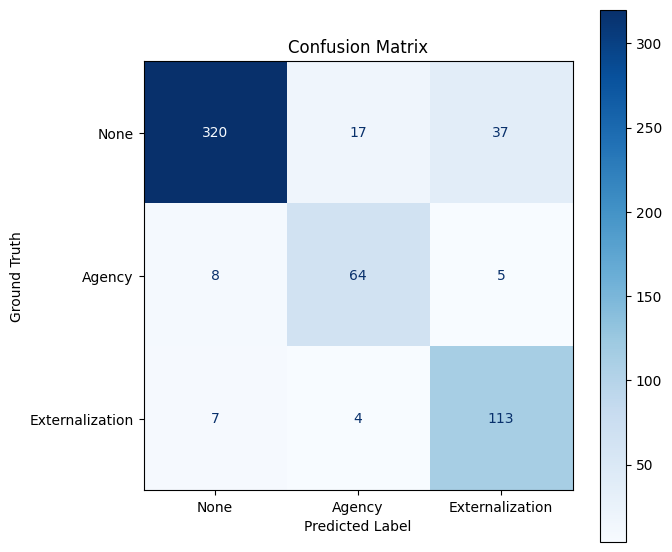

In [24]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["None", "Agency", "Externalization"]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

ax.set_title("Confusion Matrix")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Ground Truth")

plt.tight_layout()

# Save as PNG
fig.savefig(
    "img/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Normalized (percentage of each ground-truth category assigned to each class)

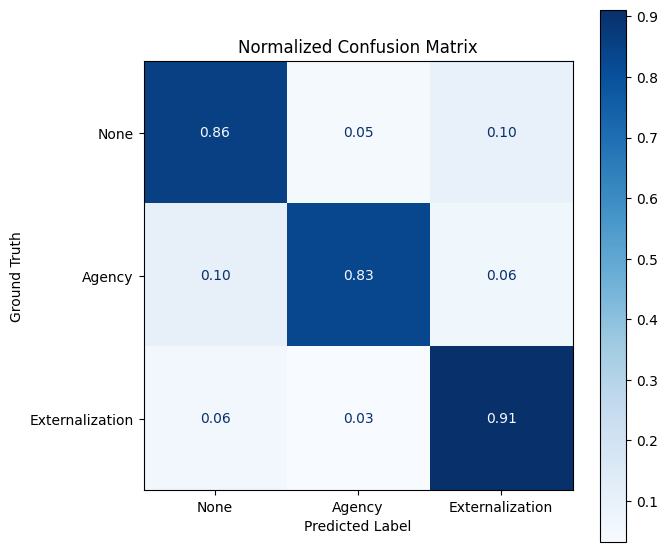

In [25]:
cm_normalized = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    normalize="true"
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=["None", "Agency", "Externalization"]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f"
)

ax.set_title("Normalized Confusion Matrix")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Ground Truth")

plt.tight_layout()

# Save as PNG
fig.savefig(
    "img/confusion_matrix_normalized.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()